# Tutorial for the YamboCoulombParser class

This tutorial describes the `YamboCoulombParser` class, which reads the Coulomb interaction used by a Yambo run from
the `ndb.cutoff` and `ndb.RIM` databases:

- `ndb.cutoff` contains the `bare_qpg` of Yambo, $b_\mathbf{G}(\mathbf{q})$, with $v_\mathbf{G}(\mathbf{q}) =
  4\pi/b_\mathbf{G}(\mathbf{q})^2$ ($b = |\mathbf{q}+\mathbf{G}|$ without cutoff), for the first G vectors of the global list
  of the `SAVE`. These are the values used in the screening: the matrices $X = v^{1/2}\chi v^{1/2}$ of the screening
  databases contain exactly these $v^{1/2}$;
- `ndb.RIM` contains the average of $1/b_\mathbf{G}(\mathbf{q}+\mathbf{q}')^2$ over the small cell of the BZ around each q
  point, computed with random points (random integration method, RIM). Yambo uses it in the exchange self-energy, in the
  head of the BSE kernel and to build `ndb.RIM_W`; it is needed at $\mathbf{q} = 0$, where v diverges.

Both databases depend only on the geometry of the run (cell, q grid, cutoff, random points), so they can be shared by
several runs; a run may have one of them, both or none, and they may be in different folders.

We use a monolayer of hexagonal boron nitride (hBN) with the slab cutoff of the Coulomb interaction, which removes the
interaction between the periodic replicas of the layer along z. The files of the tutorial are written in the
`YamboCoulombParser_tutorial` folder.

In [1]:
# useful to autoreload the module without restarting the kernel
%load_ext autoreload
%autoreload 2

import os, shutil, datetime
import numpy as np
import matplotlib.pyplot as plt
from mppi import InputFiles as I, Calculators as C
from mppi.Calculators import Tools
from mppi.Parsers import YamboCoulombParser, YamboScreeningParser

print('Notebook executed on', datetime.datetime.now().strftime('%d/%m/%Y %H:%M'))

Notebook executed on 18/11/2026 14:30


## Preparation of the data

The DFT computations (scf and nscf with 60 bands on a 12x12x1 k grid) are performed with QuantumESPRESSO on one
node through slurm. The hBN layer has $a = 2.504$ Å, the cell is 40 bohr along z and the atoms are in the plane
$z_0 = -3.15$ bohr.

In [2]:
run_dir = 'YamboCoulombParser_tutorial'
if os.path.isdir(run_dir):
    shutil.rmtree(run_dir)
qe_module = '/home/dalessandro/module_script/qe_module'
yambo_module = '/home/dalessandro/module_script/yambo_module'

inp = I.PwInput()
inp.set_prefix('hbn')
inp.set_pseudo_dir(pseudo_dir='pseudos', abs_path=True)
inp.set_lattice(ibrav=4, celldm1=4.731873875401624, celldm3=8.453310686900958)
inp.add_atom('B', 'B_ONCV_PBE-1.2.upf', 10.811)
inp.add_atom('N', 'N_ONCV_PBE-1.2.upf', 14.007)
inp.set_atoms_number(2)
inp.set_atomic_positions([['B', [0., 0.5773502692, -0.6649361022]], ['N', [0.5, 0.2886751346, -0.6649361022]]],
                         type='alat')
inp.set_energy_cutoff(60)
inp.set_kpoints(points=[12, 12, 1])

rr = C.RunRules(scheduler='slurm', partition='all12h', memory='125000', time='11:59:00', nodes=1,
                ntasks_per_node=16, cpus_per_task=2, omp_num_threads=2, pre_processing=qe_module)
qe = C.QeCalculator(rr, activate_BeeOND=True, verbose=False)
inp.set_scf()
inp.set_outdir('out_scf')
qe.run(input=inp, run_dir=run_dir, name='hbn_scf')
inp.set_nscf(nbnd=60, force_symmorphic=True)
inp.set_outdir('out_nscf')
qe.run(input=inp, run_dir=run_dir, name='hbn_nscf', source_dir=os.path.join(run_dir, 'out_scf', 'hbn.save'));

Initialize a QuantumESPRESSO calculator with scheduler slurm
Submitted batch job 62095


Submitted batch job 62096


Then the `SAVE` is built and two Yambo runs are performed through slurm: a run with the slab cutoff and the RIM
only (`yambo -r`), which writes `ndb.cutoff` and `ndb.RIM` in the folder `ndb_rim_cutoff`, and the static screening
(`yambo -X s`, 313 G vectors, 60 bands), which reads them through the `jobname` list and writes `ndb.em1s` in the folder
`em1s`.

In [3]:
yambo_dir = os.path.join(run_dir, 'yambo')
Tools.init_yambo_dir(yambo_dir=yambo_dir, input_dir=os.path.join(run_dir, 'out_nscf', 'hbn.save'),
                     p2y_command='OMP_NUM_THREADS=1 mpirun -np 1 p2y',
                     yambo_command='OMP_NUM_THREADS=1 mpirun -np 1 yambo')

rr = C.RunRules(scheduler='slurm', partition='all12h', memory='125000', time='11:59:00', nodes=1,
                ntasks_per_node=32, cpus_per_task=1, omp_num_threads=1, pre_processing=yambo_module)
code = C.YamboCalculator(rr, activate_BeeOND=True, verbose=False)
cmd = 'OMP_NUM_THREADS=1 mpirun -np 1 yambo'      # only to generate the inputs

def coulomb_variables(inp):
    inp.set_scalar_variables(CUTGeo='slab z')
    inp.set_array_variables(RandQpts=1000000)
    inp.set_array_variables(units='RL', RandGvec=101)

inp = I.YamboInput(args='%s -r -V all' % cmd, folder=yambo_dir)
coulomb_variables(inp)
code.run(input=inp, run_dir=yambo_dir, name='ndb_rim_cutoff', jobname='ndb_rim_cutoff')

inp = I.YamboInput(args='%s -r -X s -V all' % cmd, folder=yambo_dir)
coulomb_variables(inp)
inp.set_array_variables(units='Ha', NGsBlkXs=4.)
inp.set_array_variables(BndsRnXs=[1, 60], LongDrXs=[1., 1., 0.])
inp.set_scalar_variables(X_and_IO_ROLEs='q.g.k.c.v', X_and_IO_CPU='1.1.4.8.1', DIP_ROLEs='k.c.v', DIP_CPU='4.8.1')
code.run(input=inp, run_dir=yambo_dir, name='em1s', jobname=['em1s', 'ndb_rim_cutoff'])
print(sorted(os.listdir(os.path.join(yambo_dir, 'ndb_rim_cutoff'))))

Create the folder path YamboCoulombParser_tutorial/yambo
Executing command: cd YamboCoulombParser_tutorial/yambo; OMP_NUM_THREADS=1 mpirun -np 1 p2y -I ../out_nscf/hbn.save


Build the r_setup in the yambo_dir path YamboCoulombParser_tutorial/yambo


Initialize a Yambo calculator with scheduler slurm


Submitted batch job 62097


Submitted batch job 62098


['LOG', 'ndb.RIM', 'ndb.cutoff', 'ndb_rim_cutoff.in', 'r-ndb_rim_cutoff_rim_cut']


## Reading the databases

The object is built from the `SAVE` (lattice, lattice parameters of Yambo and global list of the G vectors) and from
the paths of `ndb.cutoff` and `ndb.RIM`, given independently (the file or the folder that contains it). At least one
of them is required; if both are given, the class checks that they describe the same q grid.

In [4]:
save = os.path.join(yambo_dir, 'SAVE')
shared = os.path.join(yambo_dir, 'ndb_rim_cutoff')
coul = YamboCoulombParser(save, cutoff=shared, rim=shared)

Coulomb interaction: cutoff "slab z"
number of q points 19 (IBZ), 144 (BZ)
ndb.cutoff: YamboCoulombParser_tutorial/yambo/ndb_rim_cutoff/ndb.cutoff, 8269 G vectors
ndb.RIM: YamboCoulombParser_tutorial/yambo/ndb_rim_cutoff/ndb.RIM, 101 G vectors (diagonal), 1000000 random points


The two files can be in different folders: here we copy `ndb.RIM` in another folder and pass the paths of the
files. With `ndb.RIM` only, the cutoff is not known (the `CUTOFF` field written in `ndb.RIM` is not reliable) and the
point values of v are computed without cutoff: the class prints a warning.

In [5]:
other = os.path.join(run_dir, 'rim_copy')
os.makedirs(other, exist_ok=True)
shutil.copy(os.path.join(shared, 'ndb.RIM'), other)
coul2 = YamboCoulombParser(save, cutoff=os.path.join(shared, 'ndb.cutoff'), rim=os.path.join(other, 'ndb.RIM'),
                           verbose=False)
print('same data from different folders:', np.allclose(coul2.coulomb_rim(3), coul.coulomb_rim(3)))
only_rim = YamboCoulombParser(save, rim=other)

same data from different folders: True
Coulomb interaction: cutoff "none"
number of q points 19 (IBZ), 144 (BZ)
ndb.RIM: YamboCoulombParser_tutorial/rim_copy/ndb.RIM, 101 G vectors (diagonal), 1000000 random points


In [6]:
print('q points: %d (IBZ), %d (BZ); G vectors of ndb.cutoff: %d, of ndb.RIM: %d (diagonal: %s)' % (
      coul.nq, coul.nqbz, coul.ng_cut, coul.rim_ng, coul.rim_is_diagonal))
print('random points of the RIM: %d, BZ volume: Monte Carlo %.5f, exact %.5f bohr^-3' % (
      coul.rim_points, coul.rim_RL_volume, coul.RL_volume))

q points: 19 (IBZ), 144 (BZ); G vectors of ndb.cutoff: 8269, of ndb.RIM: 101 (diagonal: True)
random points of the RIM: 1000000, BZ volume: Monte Carlo 0.32008, exact 0.31980 bohr^-3


## Point values and slab cutoff

`bare_qpg(iq, ng)` and `coulomb(iq, ng)` give $b_\mathbf{G}(\mathbf{q})$ and $v_\mathbf{G}(\mathbf{q})$ on the first ng G
vectors (the q points are numbered from 1, as in Yambo). For the slab cutoff along z Yambo uses

$$b_\mathbf{G}(\mathbf{q}) = \frac{|\mathbf{q}+\mathbf{G}|}{\sqrt{1 - e^{-Q_\parallel l}\cos((q+G)_z l)}}, \qquad l = c/2 ,$$

with $Q_\parallel$ the in-plane part of $\mathbf{q}+\mathbf{G}$. `check_slab` compares the database with this formula: since
`ndb.cutoff` does not store the G vectors, the agreement also checks that its values belong to the G list of the `SAVE`.
At $\mathbf{q} = 0$, G = 0, without RIM Yambo replaces the value with an average over a circle of the area of the small
cell of the BZ; with RIM (as here) it keeps the value at $|\mathbf{q}| = 10^{-5}$, which `check_slab(rim=False)` shows.

In [7]:
dev = coul.check_slab()
dev = coul.check_slab(rim=False)

ndb.cutoff vs analytic slab formula, max relative deviation: 2.5e-07 (q != 0), 1.7e-05 (q = 0, G != 0), 1.6e-05 (q = 0, G = 0)
ndb.cutoff vs analytic slab formula, max relative deviation: 2.5e-07 (q != 0), 1.7e-05 (q = 0, G != 0), 9.9e-01 (q = 0, G = 0)


The cut interaction differs from the 3D one $4\pi/|\mathbf{q}+\mathbf{G}|^2$ for the G vectors with $G_z = 0$:
with $G_z = 2\pi n/c$, the factor $1 - e^{-Ql}\cos(G_z l)$ is $1 - e^{-Qc/2}$ for even $n$ (so for $G_z = 0$ and small
$Q$, $v \simeq 2\pi c/Q$: the interaction of two charged planes per unit area, times the length c of the cell, while for
even $n \neq 0$ v vanishes for $Q \to 0$) and $1 + e^{-Qc/2}$ for odd $n$. The plot shows the G = 0 component.

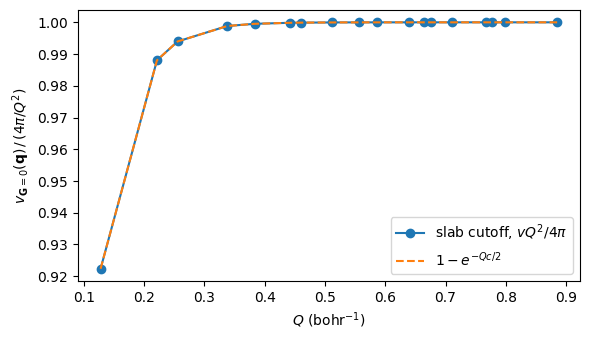

In [8]:
qn = np.linalg.norm(coul.q[:, :2], axis=1)
g0 = 0                                                     # G = 0 is the first G vector
v0 = np.array([coul.coulomb(iq, 1)[g0] for iq in range(2, coul.nq + 1)])
order = np.argsort(qn[1:])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(qn[1:][order], (v0 * qn[1:]**2 / (4 * np.pi))[order], 'o-', label=r'slab cutoff, $v Q^2/4\pi$')
ax.plot(qn[1:][order], (1 - np.exp(-qn[1:] * coul.alat[2] / 2))[order], '--', label=r'$1 - e^{-Qc/2}$')
ax.set_xlabel(r'$Q$ (bohr$^{-1}$)')
ax.set_ylabel(r'$v_{\mathbf{G}=0}(\mathbf{q})\,/\,(4\pi/Q^2)$')
ax.legend()
plt.tight_layout()
plt.show()

## Cell averages of the RIM

`coulomb_rim(iq)` gives the average of v over the small cell of the BZ around q,
$\langle v\rangle_\mathbf{G}(\mathbf{q}) = 4\pi R_{\mathbf{G}\mathbf{G}}(\mathbf{q})/(2w_q)$ with R the `RIM_qpg` of Yambo and
$w_q = (\Omega_{BZ}/N_q)/(2\pi)^3$ (a vector for a diagonal RIM, a matrix otherwise). Far from q = 0 the average is close
to the point value; the deviation grows for small $|\mathbf{q}+\mathbf{G}|$, where v changes quickly in the cell. At
$\mathbf{q} = 0$ the point value is not usable: for G = 0 it is the value at $|\mathbf{q}| = 10^{-5}$, while the average
includes the integrable divergence of v; for the G vectors along z with even $n$ the cut interaction at
$\mathbf{q}\to 0$ almost vanishes, while its average over the cell is finite.

In [9]:
for iq in [1, 2, 3, 5, 10]:
    ratio = coul.coulomb_rim(iq) / coul.coulomb(iq, coul.rim_ng)
    print('iq = %2d, |q| = %.3f bohr^-1: <v>/v at G = 0 %.4g, min %.4g, max %.4g over the %d G vectors' % (
          iq, np.linalg.norm(coul.q[iq - 1]), ratio[0], ratio.min(), ratio.max(), coul.rim_ng))

iq =  1, |q| = 0.000 bohr^-1: <v>/v at G = 0 0.0002217, min 0.0002217, max 2848 over the 101 G vectors
iq =  2, |q| = 0.128 bohr^-1: <v>/v at G = 0 1.11, min 0.9712, max 1.11 over the 101 G vectors
iq =  3, |q| = 0.256 bohr^-1: <v>/v at G = 0 1.035, min 0.9961, max 1.035 over the 101 G vectors
iq =  5, |q| = 0.511 bohr^-1: <v>/v at G = 0 1.01, min 0.9998, max 1.01 over the 101 G vectors
iq = 10, |q| = 0.461 bohr^-1: <v>/v at G = 0 1.012, min 0.9996, max 1.012 over the 101 G vectors


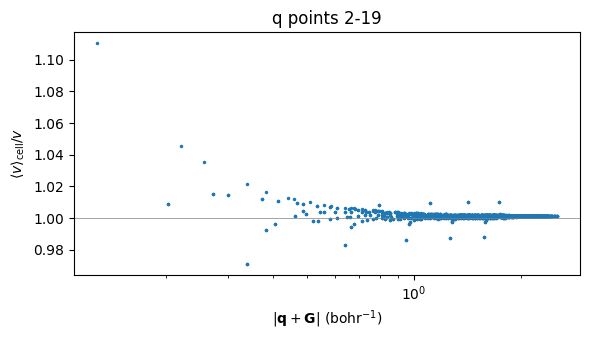

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for iq in range(2, coul.nq + 1):
    qG = np.linalg.norm(coul.q[iq - 1] + coul.G[:coul.rim_ng], axis=1)
    ax.plot(qG, coul.coulomb_rim(iq) / coul.coulomb(iq, coul.rim_ng), '.', color='C0', ms=3)
ax.axhline(1, color='gray', lw=0.5)
ax.set_xscale('log')
ax.set_xlabel(r'$|\mathbf{q}+\mathbf{G}|$ (bohr$^{-1}$)')
ax.set_ylabel(r'$\langle v\rangle_{\rm cell} / v$')
ax.set_title('q points 2-%d' % coul.nq)
plt.tight_layout()
plt.show()

## Combination with a screening database

The `YamboScreeningParser` class reads the symmetrized matrices $X = v^{1/2}\chi v^{1/2} = \epsilon^{-1} - 1$, which
need no Coulomb interaction. The quantities in physical units combine the two parsers: the $v^{1/2}$ inside X are those of
`ndb.cutoff`, on the first G vectors of the `SAVE` (the G vectors of the screening database are the first ng of the same
list). For instance the screened interaction is $W = v^{1/2}(1+X)v^{1/2}$ and the reducible response
$\chi = v^{-1/2}Xv^{-1/2}$.

In [11]:
scr = YamboScreeningParser(os.path.join(yambo_dir, 'em1s'), save)
print('G vectors of the screening database = first %d G of the SAVE:' % scr.ng, np.allclose(scr.G, coul.G[:scr.ng]))
print('same q points:', np.allclose(scr.q, coul.q, atol=1e-6))

iq = 2
X = scr.get_X(iq)[0]                                       # static screening
s = np.sqrt(coul.coulomb(iq, scr.ng))
W = s[:, None] * (np.eye(scr.ng) + X) * s[None, :]
chi = X / s[:, None] / s[None, :]
print('iq = %d: W_00/v_0 = eps^-1_00 = %.4f' % (iq, (W[0, 0] / s[0]**2).real))

Screening database YamboCoulombParser_tutorial/yambo/em1s/ndb.em1s
number of q points 19 - number of G vectors 313 - bands 1-60 - kernel HARTREE - cutoff slab z
frequencies (eV): [0.+0.001j]
G vectors of the screening database = first 313 G of the SAVE: True
same q points: True
iq = 2: W_00/v_0 = eps^-1_00 = 0.7669


In the mixed representation $M(\mathbf{Q}; z, z')$ of a 2D system (`planar` method of `YamboScreeningParser`, on the
block $\mathbf{G}_\parallel = \mathbf{G}'_\parallel$) the slab-cut Coulomb interaction is
$v(\mathbf{Q}; z, z') = (2\pi/Q)e^{-Q|z-z'|}$ for $|z-z'| < c/2$. We check it at the first q point after $\Gamma$ with the
diagonal matrix of v, both on the G vectors of the screening database (37 values of $G_z$ for $\mathbf{G}_\parallel = 0$)
and directly on the 109 values of $G_z$ of `ndb.cutoff`: the truncation of the sum on $G_z$ smooths the cusp at
$z = z'$.

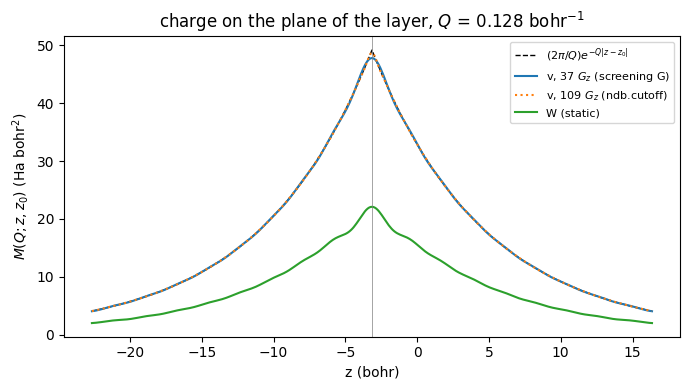

max relative deviation from (2pi/Q) e^{-Q|z - z0|} for |z - z0| > 2 bohr: 2.0e-03 (ndb.cutoff G), 1.4e-02 (screening G)


In [12]:
from mppi.Parsers import YamboDftParser
atoms = YamboDftParser(os.path.join(save, 'ns.db1'), verbose=False).atomic_positions
z0 = np.mean([pos[2] for name, pos in atoms])              # plane of the layer (bohr)
c_len = scr.lattice[2, 2]
Q = np.linalg.norm(scr.inplane_Q(iq)[:2])
z = np.linspace(z0 - c_len / 2 + 0.5, z0 + c_len / 2 - 0.5, 401)
exact = 2 * np.pi / Q * np.exp(-Q * np.abs(z - z0))

v_scr = scr.planar(np.diag(s**2), iq, (0, 0), z, z0).real[:, 0]
sel = np.all(coul.G_crystal[:coul.ng_cut, :2] == 0, axis=1)  # G_par = 0 in the G list of ndb.cutoff
Gz = coul.G[:coul.ng_cut][sel, 2]
v_cut = (np.exp(1j * np.outer(z - z0, Gz)) @ coul.coulomb(iq)[sel]).real / c_len
W_pl = scr.planar(W, iq, (0, 0), z, z0).real[:, 0]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(z, exact, 'k--', lw=1, label=r'$(2\pi/Q)e^{-Q|z-z_0|}$')
ax.plot(z, v_scr, label='v, %d $G_z$ (screening G)' % np.sum(np.all(scr.G_crystal[:, :2] == 0, axis=1)))
ax.plot(z, v_cut, ':', label='v, %d $G_z$ (ndb.cutoff)' % len(Gz))
ax.plot(z, W_pl, label='W (static)')
ax.axvline(z0, color='gray', lw=0.5)
ax.set_xlabel('z (bohr)')
ax.set_ylabel(r'$M(Q; z, z_0)$ (Ha bohr$^2$)')
ax.set_title(r'charge on the plane of the layer, $Q$ = %.3f bohr$^{-1}$' % Q)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
far = np.abs(z - z0) > 2
print('max relative deviation from (2pi/Q) e^{-Q|z - z0|} for |z - z0| > 2 bohr: %.1e (ndb.cutoff G), %.1e (screening G)' % (
      np.abs(v_cut / exact - 1)[far].max(), np.abs(v_scr / exact - 1)[far].max()))

Finally, the static screening of the layer reduces the interaction between two charges on its plane: the ratio
$W(\mathbf{Q}; z_0, z_0)/v(\mathbf{Q}; z_0, z_0)$ (both on the G vectors of the screening database) has a minimum around
$Q \simeq 0.3$ bohr$^{-1}$ and rises again for smaller Q: in a 2D system $\epsilon(Q) \simeq 1 + r_0 Q$ and the
screening vanishes for $Q\to 0$ (the smallest Q of the 12x12 grid is 0.128 bohr$^{-1}$). For large Q the ratio grows
again, since the screening of the layer decreases on lengths comparable with its thickness.

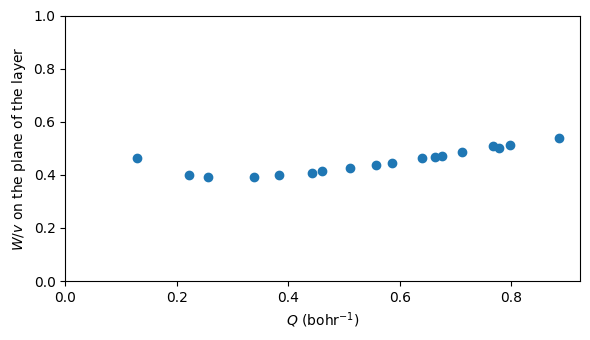

Q (bohr^-1): [0.128 0.221 0.256 0.338 0.383]  W/v: [0.462 0.4   0.393 0.392 0.398]


In [13]:
rows = []
for iq in range(2, scr.nq + 1):
    s = np.sqrt(coul.coulomb(iq, scr.ng))
    X = scr.get_X(iq)[0]
    W = s[:, None] * (np.eye(scr.ng) + X) * s[None, :]
    w = scr.planar(W, iq, (0, 0), z0, z0).real[0, 0]
    v = scr.planar(np.diag(s**2), iq, (0, 0), z0, z0).real[0, 0]
    rows.append((np.linalg.norm(scr.inplane_Q(iq)[:2]), w / v))
rows = np.array(sorted(rows))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(rows[:, 0], rows[:, 1], 'o')
ax.set_xlim(left=0)
ax.set_ylim(0, 1)
ax.set_xlabel(r'$Q$ (bohr$^{-1}$)')
ax.set_ylabel(r'$W/v$ on the plane of the layer')
plt.tight_layout()
plt.show()
print('Q (bohr^-1):', np.round(rows[:5, 0], 3), ' W/v:', np.round(rows[:5, 1], 3))